# 8. Сценарии травм и приоритеты профилактики

Данные: `OSHA_db`, 105 996 тяжёлых травм (январь 2015 – ноябрь 2025). SQL-запросы — `SQL/08_scenarios.sql`.

Здесь справочники сводятся вместе: типичные сценарии «тип происшествия → источник → часть тела», портреты крупнейших отраслей и правило 80/20 — на чём сосредоточить профилактику.

Что добавляет Python: объединение одинаковых названий, русские подписи, кривые концентрации (Парето / Лоренц) и коэффициент Джини по каждому справочнику.

In [1]:
import os
if not os.path.isdir("src"):  # ноутбук запущен из notebooks/, а не из Analysis/
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats

from src.db import query
from src.viz import set_style, tr, finish, barh_ranked, wrap, LANGS, TABLES_DIR, MAIN, ACCENT, SERIES
from src.stats import num, cramers_v, share_ci, rank_by_title
from src.labels import (norm_title, event_ru, source_ru, body_part_ru, nature_ru, sector_code,
                        SECTORS)

set_style()
TABLES_DIR.mkdir(exist_ok=True)

## 8.0. Исходные данные

In [2]:
cases = query("""
    SELECT i.id,
           i.event_code,        e.title AS event,
           i.source_code,       s.title AS source,
           i.part_of_body_code, b.title AS body_part,
           i.nature_code,       n.title AS nature,
           i.naics_code,
           i.severity_code
    FROM injuries i
    JOIN event_lookup     e ON e.code = i.event_code
    JOIN source_lookup    s ON s.code = i.source_code
    JOIN body_part_lookup b ON b.code = i.part_of_body_code
    JOIN nature_lookup    n ON n.code = i.nature_code
""")
for col in ["event", "source", "body_part", "nature"]:
    cases[col + "_key"] = cases[col].map(norm_title)
cases["sector"] = cases["naics_code"].map(sector_code)
cases["amputation"] = (cases["severity_code"] & 2) > 0
N = len(cases)

# самое частое написание для каждого объединённого названия
NAME = {col: rank_by_title(cases[col], cases[code])["title"]
        for col, code in [("event", "event_code"), ("source", "source_code"),
                          ("body_part", "part_of_body_code"), ("nature", "nature_code")]}
RU = {"event": event_ru, "source": source_ru, "body_part": body_part_ru, "nature": nature_ru}
print(f"Случаев: {num(N)}")

Случаев: 105 996


## 8.1. Топ-15 сценариев «тип происшествия → источник → часть тела»

In [3]:
sc = (cases.groupby(["event_key", "source_key", "body_part_key"])
      .agg(cases=("id", "size"), pct_amputation=("amputation", "mean"))
      .sort_values("cases", ascending=False).reset_index())
for col in ["event", "source", "body_part"]:
    sc[col] = sc[col + "_key"].map(NAME[col])
sc["pct_of_all"] = 100 * sc["cases"] / N
sc["pct_amputation"] *= 100
sc = sc[["event", "source", "body_part", "cases", "pct_of_all", "pct_amputation"]]
sc.index += 1
print(f"Сценариев в данных: {num(len(sc))}; топ-25 покрывают {sc['pct_of_all'].head(25).sum():.1f}% случаев")
sc.head(25).round(2).to_csv(TABLES_DIR / "08_1_top_scenarios.csv", encoding="utf-8-sig")
sc.head(25).round(2)

Сценариев в данных: 42 797; топ-25 покрывают 6.8% случаев


,event,source,body_part,cases,pct_of_all,pct_amputation
1,Exposure to environmental heat,Heat-environmental,BODY SYSTEMS,2190,2.07,0.05
2,Fall on same level due to tripping over an object,"Floor, n.e.c.",Hip(s),729,0.69,0.00
3,Fall on same level due to slip or trip,Other constructed surface,Hip joint(s),409,0.39,0.49
4,Exposure to environmental heat outdoor,Heat-environmental,BODY SYSTEMS,319,0.30,0.00
5,Fall on same level due to slipping,"Floor, n.e.c.",Hip(s),295,0.28,0.00
6,Struck by or caught in swinging door or gate,"Doors, except garage and vehicle",Fingertip(s),229,0.22,95.63
7,Struck against moving part of machinery or equ...,Table saws,"Finger(s), fingernail(s), n.e.c.",225,0.21,97.78
8,"Fall on same level, n.e.c.","Floor, n.e.c.",Hip(s),225,0.21,0.00
9,Struck against moving part of machinery or equ...,Butchering machinery,Fingertip(s),198,0.19,94.44
10,Caught in running equipment or machinery durin...,"Machinery, unspecified",Fingertip(s),189,0.18,96.83


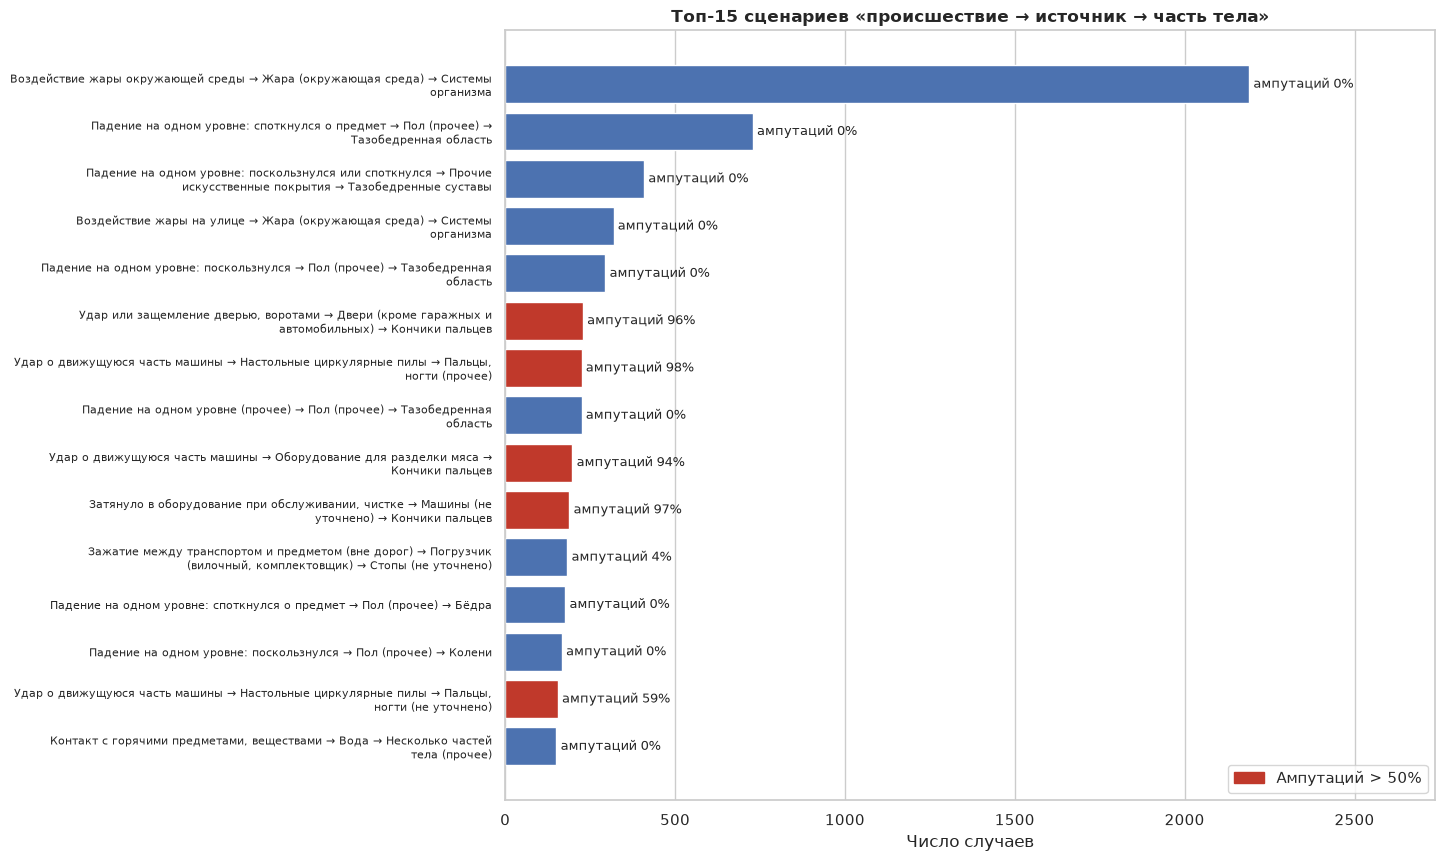

In [4]:
t = sc.head(15)
for lang in LANGS:
    if lang == "ru":
        labels = [f"{event_ru(e)} → {source_ru(s)} → {body_part_ru(b)}" for e, s, b in zip(t["event"], t["source"], t["body_part"])]
    else:
        labels = [f"{e} → {s} → {b}" for e, s, b in zip(t["event"], t["source"], t["body_part"])]
    fig, ax = plt.subplots(figsize=(12, 10))
    barh_ranked(ax, labels, t["cases"], notes=[tr(f"ампутаций {a:.0f}%", f"amputations {a:.0f}%", lang)
                                               for a in t["pct_amputation"]],
                color=np.where(t["pct_amputation"] > 50, ACCENT, MAIN), width=70)
    ax.margins(x=0.25)
    ax.tick_params(axis="y", labelsize=8)
    ax.set_title(tr("Топ-15 сценариев «происшествие → источник → часть тела»",
                    "Top 15 scenarios: event → source → body part", lang))
    ax.set_xlabel(tr("Число случаев", "Number of cases", lang))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ACCENT)],
              labels=[tr("Ампутаций > 50%", "Amputations > 50%", lang)], loc="lower right")
    finish(fig, "08_1_top_scenarios", lang)

## 8.2. Портреты 8 крупнейших секторов

Для каждого сектора — самый частый тип происшествия, источник, часть тела и вид травмы (доля внутри сектора), с объединёнными названиями.

In [5]:
top_sectors = cases["sector"].value_counts().head(8).index
rows = []
for s in top_sectors:
    g = cases[cases["sector"] == s]
    row = {"sector_ru": SECTORS[s][0], "sector_en": SECTORS[s][1], "cases": len(g),
           "pct_amputation": 100 * g["amputation"].mean()}
    for col in ["event", "source", "body_part", "nature"]:
        vc = g[col + "_key"].value_counts()
        title = NAME[col][vc.index[0]]
        row[f"top_{col}"] = title
        row[f"top_{col}_ru"] = RU[col](title)
        row[f"{col}_pct"] = 100 * vc.iloc[0] / len(g)
    rows.append(row)
portrait = pd.DataFrame(rows)
portrait.round(1).to_csv(TABLES_DIR / "08_2_sector_portraits.csv", index=False, encoding="utf-8-sig")
portrait[["sector_ru", "cases", "pct_amputation", "top_event_ru", "event_pct", "top_source_ru", "source_pct",
          "top_body_part_ru", "body_part_pct", "top_nature_ru", "nature_pct"]].round(1)

,sector_ru,cases,pct_amputation,top_event_ru,event_pct,top_source_ru,source_pct,top_body_part_ru,body_part_pct,top_nature_ru,nature_pct
0,Обрабатывающая промышленность,34472,44.7,Затянуло в работающее оборудование (штатная ра...,13.7,"Погрузчик (вилочный, комплектовщик)",4.2,Кончики пальцев,17.3,Ампутации,37.7
1,Строительство,19021,15.4,Падение с высоты (не уточнено),10.8,Крыши,3.7,Несколько частей тела (прочее),8.4,Переломы,38.8
2,Транспорт и складирование,9381,15.1,Падение с высоты (не уточнено),7.7,"Погрузчик (вилочный, комплектовщик)",12.7,Системы организма,7.0,Переломы,40.4
3,Розничная торговля,8111,17.8,Падение на одном уровне: споткнулся о предмет,8.4,Пол (прочее),14.8,Тазобедренная область,9.8,Переломы,43.4
4,Оптовая торговля,6121,26.2,Падение с высоты (не уточнено),7.0,"Погрузчик (вилочный, комплектовщик)",10.3,Кончики пальцев,9.8,Переломы,35.0
5,"Адм. услуги, утилизация отходов",5910,19.5,Падение с высоты (не уточнено),7.9,Жара (окружающая среда),5.3,Системы организма,8.4,Переломы,33.8
6,"Здравоохранение, соц. помощь",5018,7.1,Падение на одном уровне: поскользнулся,14.3,Пол (прочее),21.9,Тазобедренная область,10.3,Переломы,49.6
7,"Добыча полезных ископаемых, нефти, газа",2843,29.7,"Сдавило смещающимися предметами, оборудованием",9.3,Нефтяные буровые установки,17.9,"Пальцы, ногти (прочее)",12.8,Переломы,29.2


## 8.3. Парето по источникам

SQL 8.3 строит список источников, дающих 80% случаев, по точным кодам. Здесь — кривая накопленной доли по объединённым названиям.

In [6]:
src = rank_by_title(cases["source"], cases["source_code"]).reset_index(drop=True)
src["cum_pct"] = src["pct"].cumsum()
n80 = int((src["cum_pct"] < 80).sum() + 1)
print(f"Источников в данных (объединённых названий): {len(src)}; 80% случаев дают {n80} "
      f"({100 * n80 / len(src):.1f}% источников); первые 10 — {src['cum_pct'].iloc[9]:.1f}%")
src["source_ru"] = src["title"].map(source_ru)
src.index += 1
src.head(n80).round(2).to_csv(TABLES_DIR / "08_3_pareto_sources.csv", encoding="utf-8-sig")
src.head(20).round(2)

Источников в данных (объединённых названий): 1354; 80% случаев дают 212 (15.7% источников); первые 10 — 24.2%


,title,codes,cases,pct,cum_pct,source_ru
1,"Floor, n.e.c.",6629,5035,4.75,4.75,Пол (прочее)
2,"Forklift, order picker, platform truck-powered",8621,4600,4.34,9.09,"Погрузчик (вилочный, комплектовщик)"
3,Nonclassifiable,9999,2780,2.62,11.71,Не классифицировано
4,"Floors, walkways, ground surfaces, unspecified",660,2704,2.55,14.26,"Полы, проходы, поверхность земли"
5,Heat-environmental,"9262, 9542",2614,2.47,16.73,Жара (окружающая среда)
6,"Machinery, unspecified",30,1930,1.82,18.55,Машины (не уточнено)
7,Other constructed surface,6624,1916,1.81,20.36,Прочие искусственные покрытия
8,Step ladders,"733, 7422",1433,1.35,21.71,Стремянки
9,"Ladders, unspecified",740,1357,1.28,22.99,Лестницы (не уточнено)
10,Pallet jack-powered,8623,1319,1.24,24.23,Электрическая паллетная тележка


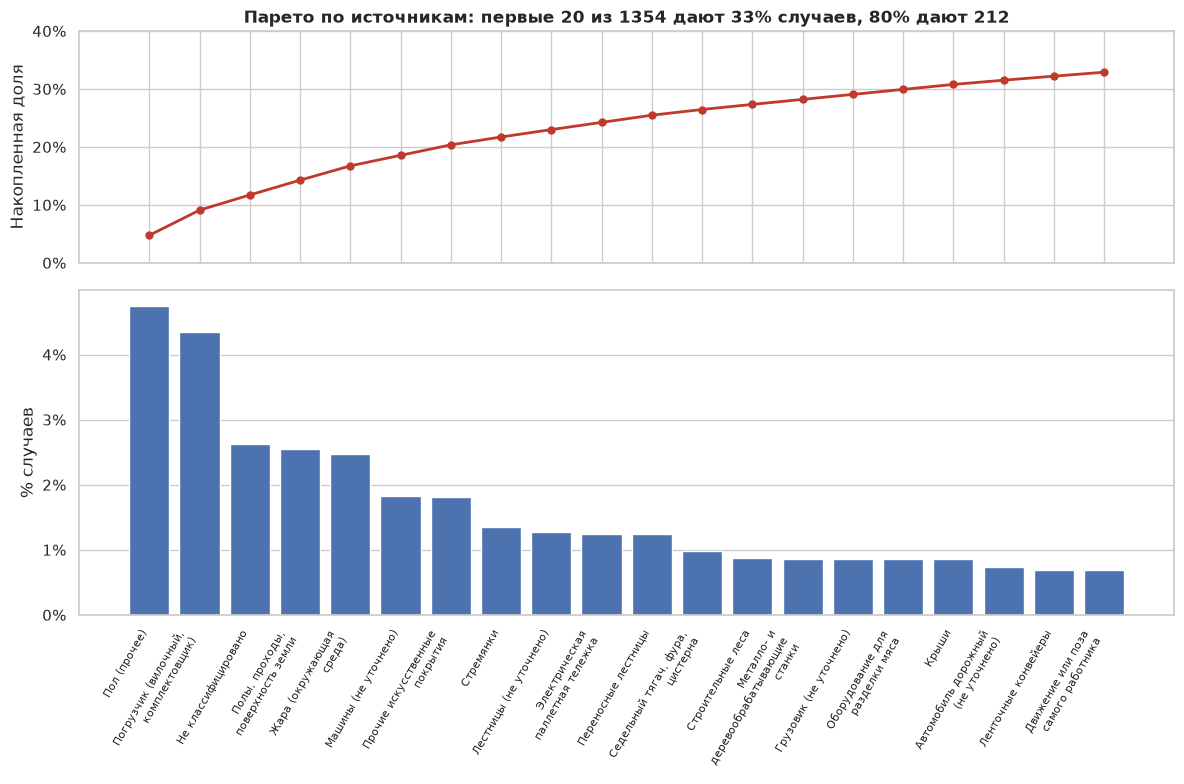

In [7]:
t = src.head(20)
for lang in LANGS:
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
    x = np.arange(len(t))
    ax1.plot(x, t["cum_pct"], color=ACCENT, marker="o", ms=5, lw=2)
    ax1.set_ylim(0, 40)
    ax1.set_ylabel(tr("Накопленная доля", "Cumulative share", lang))
    ax1.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax1.set_title(tr(f"Парето по источникам: первые 20 из {len(src)} дают {t['cum_pct'].iloc[-1]:.0f}% случаев, "
                     f"80% дают {n80}",
                     f"Pareto of sources: the first 20 of {len(src)} give {t['cum_pct'].iloc[-1]:.0f}% of cases, "
                     f"80% need {n80}", lang))
    ax2.bar(x, t["pct"], color=MAIN)
    ax2.set_ylabel(tr("% случаев", "% of cases", lang))
    ax2.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax2.set_xticks(x, [wrap(n, 22) for n in (t["source_ru"] if lang == "ru" else t["title"])],
                   rotation=60, ha="right", fontsize=8)
    ax2.grid(axis="x", visible=False)
    fig.tight_layout()
    finish(fig, "08_3_pareto_sources", lang)

## 8.4. Правило 80/20 по всем справочникам

Для каждого справочника: сколько кодов покрывают 80% случаев (как в SQL 8.4, по точным кодам) и коэффициент Джини (0 — случаи распределены по кодам равномерно, 1 — все в одном коде). Кривые показывают накопленную долю случаев в зависимости от доли кодов (коды по убыванию частоты).

In [8]:
DIMS = {
    "nature_code": ("Характер травмы (Nature)", "Nature of injury"),
    "event_code": ("Тип происшествия (Event)", "Event"),
    "part_of_body_code": ("Часть тела", "Part of body"),
    "source_code": ("Источник (Source)", "Source"),
    "naics_code": ("Отрасль (NAICS, полный код)", "Industry (full NAICS)"),
}

def gini(counts):
    x = np.sort(np.asarray(counts, dtype=float))
    n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum())

rows, curves = [], {}
for col, (ru, en) in DIMS.items():
    vc = cases[col].value_counts()
    cum = vc.cumsum() / vc.sum() * 100
    n80 = int((cum < 80).sum() + 1)
    curves[col] = (np.arange(1, len(vc) + 1) / len(vc) * 100, cum.to_numpy())
    rows.append({"dimension": ru, "codes_in_data": len(vc), "codes_for_80pct": n80,
                 "pct_of_codes": 100 * n80 / len(vc), "top1_pct": 100 * vc.iloc[0] / vc.sum(), "gini": gini(vc)})
conc = pd.DataFrame(rows).sort_values("pct_of_codes").reset_index(drop=True)
conc.round(3).to_csv(TABLES_DIR / "08_4_concentration.csv", index=False, encoding="utf-8-sig")
conc.round(2)

,dimension,codes_in_data,codes_for_80pct,pct_of_codes,top1_pct,gini
0,Характер травмы (Nature),251,13,5.18,26.90,0.92
1,Тип происшествия (Event),476,62,13.03,6.32,0.83
2,Часть тела,205,27,13.17,10.16,0.83
3,Источник (Source),1489,232,15.58,4.75,0.81
4,"Отрасль (NAICS, полный код)",1287,283,21.99,2.33,0.75


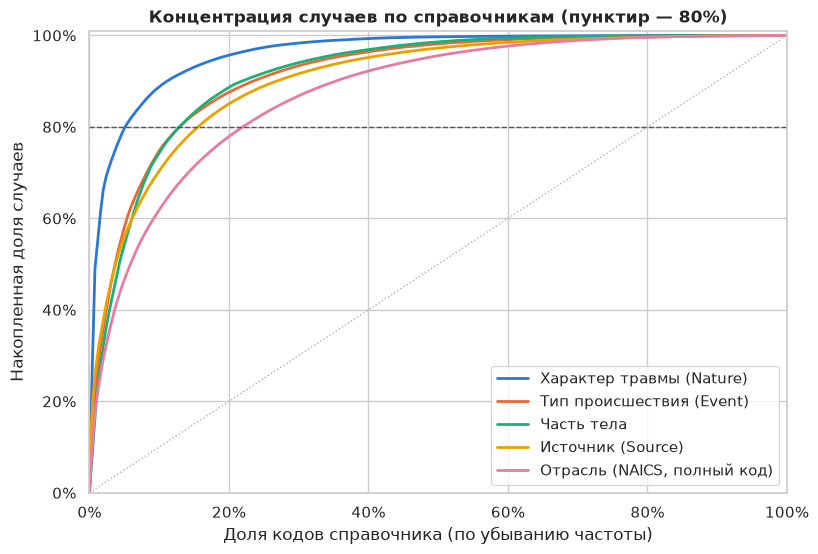

In [9]:
for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(9, 6))
    for (col, names), color in zip(DIMS.items(), SERIES):
        x, y = curves[col]
        ax.plot(np.r_[0, x], np.r_[0, y], color=color, lw=2, label=names[k])
    ax.plot([0, 100], [0, 100], color="#b0b0b0", ls=":", lw=1)
    ax.axhline(80, color="#555555", ls="--", lw=1)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 101)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xlabel(tr("Доля кодов справочника (по убыванию частоты)", "Share of codes (most frequent first)", lang))
    ax.set_ylabel(tr("Накопленная доля случаев", "Cumulative share of cases", lang))
    ax.set_title(tr("Концентрация случаев по справочникам (пунктир — 80%)",
                    "Concentration of cases by classification (dashed — 80%)", lang))
    ax.legend(loc="lower right")
    finish(fig, "08_4_concentration", lang)

## Выводы

1. **Самый массовый сценарий — тепловой удар от жары окружающей среды** (2,1% всех случаев; вместе с вариантом «на улице» — 2,4%). Следом — падения на одном уровне (споткнулся или поскользнулся на полу) с травмой тазобедренной области. Среди сценариев с ампутациями лидируют пальцы: двери и ворота, настольные циркулярные пилы, оборудование для разделки мяса, обслуживание машин — 94–98% таких случаев заканчиваются ампутацией.
2. **Сценарии очень разнообразны:** 42 797 уникальных сочетаний, топ-25 покрывают лишь 6,8% случаев. Поэтому профилактику лучше строить не по отдельным сценариям, а по группам: падения (полы, лестницы, крыши), машины без защиты, погрузчики, жара.
3. **Портреты отраслей:** в обрабатывающей промышленности главный вид травмы — ампутация (37,7%) кончиков пальцев при затягивании в оборудование; в строительстве, транспорте, торговле и здравоохранении — переломы при падениях. Ключевой источник: в транспорте, оптовой торговле и промышленности — погрузчики; в рознице и здравоохранении — пол (15–22% случаев сектора); в добыче — буровые установки (18%).
4. **Правило 80/20 выполняется для всех справочников.** Сильнее всего концентрация по характеру травмы: 13 кодов из 251 (5%) дают 80% случаев, коэффициент Джини 0,92. По типам происшествий и частям тела 80% дают ~13% кодов, по источникам — 16% (232 из 1 489 кодов), по отраслям — 22% (Джини 0,75).
5. **Вывод для профилактики:** последствия (перелом, ампутация) сосредоточены в немногих категориях, а причины (источники, отрасли) распределены шире. Наибольший эффект дадут меры против небольшого числа механизмов: защита и блокировка машин (ампутации пальцев), предотвращение падений на одном уровне и с высоты, безопасная работа с погрузчиками и защита от жары летом.